# Personal loan classification and customer segmentation
KNN and a Keras neural network predict loan acceptance; K-Means explores customer segments. Corrected portfolio edition: stratified 80/20 train/test split, fold-specific scaling for KNN, training-only K selection, and a stratified validation subset with its own training-fitted scaler for the ANN. Original test metrics are replaced by rerun results. A new independent external dataset would be needed for stronger validation after historical test inspection.


In [1]:
from pathlib import Path
DATA = Path('data')
ARTIFACTS = Path('artifacts')
RESULTS = Path('results')
ARTIFACTS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
df = pd.read_csv(DATA / 'bank_personal_loan_data.csv')
df.head(10)

Out[3]: 
   ID  Age  Experience  Income  ...  CD Account  Online  CreditCard  Personal Loan
0   1   25           1      49  ...           0       0           0              0
1   2   45          19      34  ...           0       0           0              0
2   3   39          15      11  ...           0       0           0              0
3   4   35           9     100  ...           0       0           0              0
4   5   35           8      45  ...           0       0           1              0
5   6   37          13      29  ...           0       1           0              0
6   7   53          27      72  ...           0       1           0              0
7   8   50          24      22  ...           0       0           1              0
8   9   35          10      81  ...           0       1           0              0
9  10   34           9     180  ...           0       0           0              1

[10 rows x 14 columns]


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Securities Account  5000 non-null   int64  
 10  CD Account          5000 non-null   int64  
 11  Online              5000 non-null   int64  
 12  CreditCard          5000 non-null   int64  
 13  Personal Loan       5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


In [5]:
df.describe()

Out[5]: 
                ID          Age  ...   CreditCard  Personal Loan
count  5000.000000  5000.000000  ...  5000.000000    5000.000000
mean   2500.500000    45.338400  ...     0.294000       0.096000
std    1443.520003    11.463166  ...     0.455637       0.294621
min       1.000000    23.000000  ...     0.000000       0.000000
25%    1250.750000    35.000000  ...     0.000000       0.000000
50%    2500.500000    45.000000  ...     0.000000       0.000000
75%    3750.250000    55.000000  ...     1.000000       0.000000
max    5000.000000    67.000000  ...     1.000000       1.000000

[8 rows x 14 columns]


In [6]:
df.drop(columns=['ID', 'ZIP Code'], inplace=True)
# Split before exploratory statistics or any fitted preprocessing.
df = df.drop_duplicates().reset_index(drop=True)
X = df.drop(columns='Personal Loan')
y = df['Personal Loan']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
# EDA below uses training rows only.
df = pd.concat([X_train, y_train], axis=1)
print('Training:', X_train.shape, 'Test:', X_test.shape)


Training: (3989, 11) Test: (998, 11)


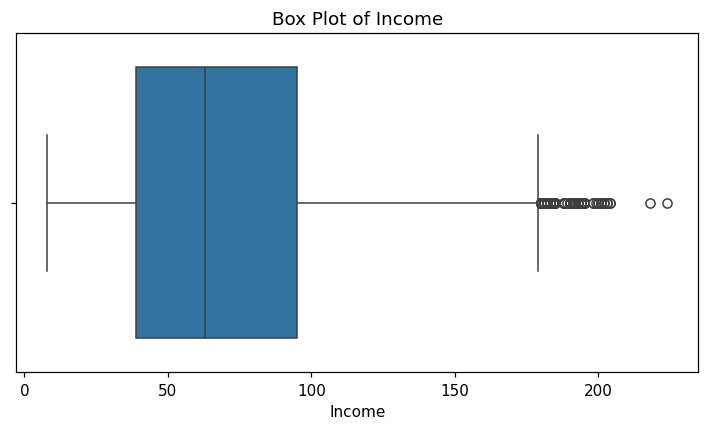

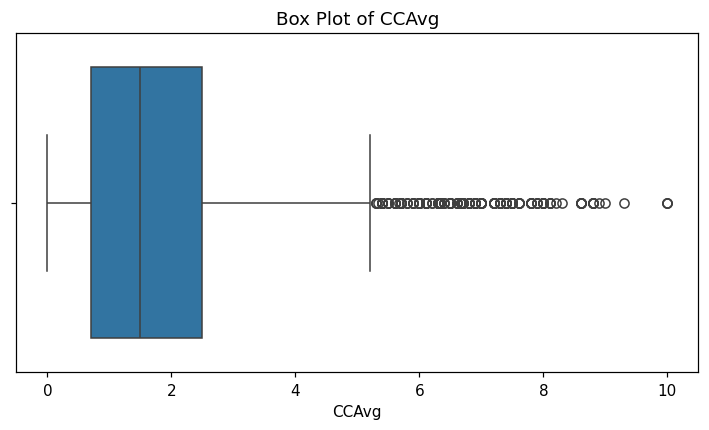

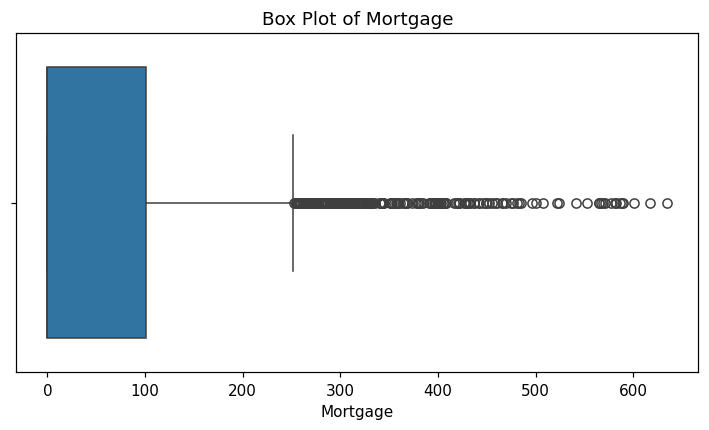

In [7]:
#box plot for income, CCavg, Mortgage
for col in ['Income', 'CCAvg', 'Mortgage']:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Box Plot of {col}')
    plt.show()

In [8]:
df.isnull().sum()

Out[8]: 
Age                   0
Experience            0
Income                0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
Personal Loan         0
dtype: int64


In [9]:
print('Training duplicates:', df.duplicated().sum())

Training duplicates: 0


In [10]:
#using z-score to count outliers
from scipy import stats
z_scores = np.abs(stats.zscore(df[['Income', 'CCAvg', 'Mortgage']]))
outliers = df[(z_scores >= 3).any(axis=1)]
print(f"Number of outliers: {outliers.shape[0]}")



Number of outliers: 162


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
cols_to_scale = ['Age', 'Experience', 'Income', 'CCAvg', 'Mortgage']
preprocessor = ColumnTransformer([('numeric', StandardScaler(), cols_to_scale)], remainder='passthrough')


In [12]:
print('Raw training features are retained until fitting the pipeline.')

Raw training features are retained until fitting the pipeline.


In [13]:
k_values = list(range(1, 21))
knn_search = GridSearchCV(
    Pipeline([('preprocessor', preprocessor), ('model', KNeighborsClassifier())]),
    {'model__n_neighbors': k_values},
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring='accuracy', n_jobs=2)
knn_search.fit(X_train, y_train)
accuracies = knn_search.cv_results_['mean_test_score']


In [14]:
best_k = knn_search.best_params_['model__n_neighbors']
print('Best k:', best_k, 'CV accuracy:', knn_search.best_score_)

Best k: 3 CV accuracy: 0.9628981487596029


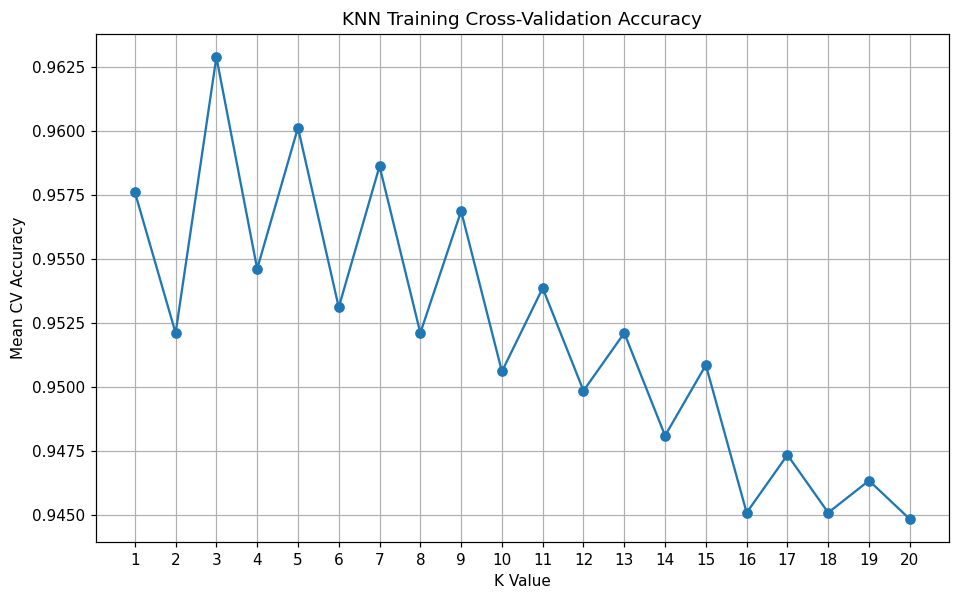

In [15]:
#plotting the accuracies for different k values
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o')
plt.title('KNN Training Cross-Validation Accuracy')
plt.xlabel('K Value')
plt.ylabel('Mean CV Accuracy')
plt.xticks(k_values)
plt.grid()
plt.show()


In [16]:
# Final KNN model with best k — evaluation
knn_final = knn_search.best_estimator_
y_pred_knn = knn_final.predict(X_test)

print(f"KNN Final Model (k={best_k})")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, digits=3))

KNN Final Model (k=3)

Confusion Matrix:
[[898   4]
 [ 30  66]]

Classification Report:
              precision    recall  f1-score   support

           0      0.968     0.996     0.981       902
           1      0.943     0.688     0.795        96

    accuracy                          0.966       998
   macro avg      0.955     0.842     0.888       998
weighted avg      0.965     0.966     0.964       998



In [17]:
#using ann
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# Fix seeds so the baseline is reproducible
tf.random.set_seed(42)
np.random.seed(42)
# ANN validation is split before fitting preprocessing.
from sklearn.base import clone
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)
ann_preprocessor = clone(preprocessor)
X_fit_ann = ann_preprocessor.fit_transform(X_fit).astype('float32')
X_val_ann = ann_preprocessor.transform(X_val).astype('float32')
X_test_ann = ann_preprocessor.transform(X_test).astype('float32')
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()


In [18]:
ann = Sequential()
ann.add(Input(shape=(X_train.shape[1],)))   # input layer = number of features
ann.add(Dense(16, activation='relu'))        # hidden layer 1
ann.add(Dense(8,  activation='relu'))         # hidden layer 2
ann.add(Dense(1,  activation='sigmoid'))  # output layer

In [19]:
ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [20]:
history = ann.fit(X_fit_ann, y_fit, epochs=20, batch_size=32, validation_data=(X_val_ann, y_val), verbose=0)
print('ANN trained for 20 epochs with explicit validation.')

ANN trained for 20 epochs with explicit validation.


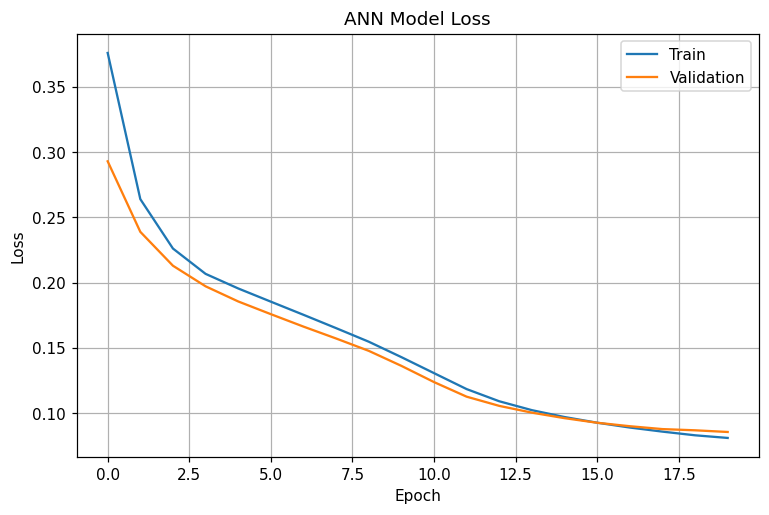

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('ANN Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.grid()
plt.show()

In [22]:
loss, accuracy = ann.evaluate(X_test_ann, y_test, verbose=0)
print(f"ANN Test Accuracy: {accuracy:.4f}")

ANN Test Accuracy: 0.9699


In [23]:
y_pred_ann = (ann.predict(X_test_ann, verbose=0) > 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_ann))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_ann, digits=3))

Confusion Matrix:
[[887  15]
 [ 15  81]]

Classification Report:
              precision    recall  f1-score   support

           0      0.983     0.983     0.983       902
           1      0.844     0.844     0.844        96

    accuracy                          0.970       998
   macro avg      0.914     0.914     0.914       998
weighted avg      0.970     0.970     0.970       998



## Q1 B) K-Means Clustering — Customer Subgroup Exploration

K-Means is an **unsupervised** method: we give it the customer features (no target label) and it finds natural groupings. The goal here is to discover whether the bank's customers fall into meaningful segments that could explain different behaviours around loan acceptance.

## Clustering scope
This separate descriptive analysis uses all customer feature rows and excludes the loan label during fitting. Silhouette and PCA describe these observed customers; they are not held-out prediction scores. Loan rates are calculated after fitting for interpretation only. The clustering count is selected from the measured silhouette scores.


In [24]:
# Imports for clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA


In [25]:
# Load a fresh copy of the data specifically for clustering
# (keeps the clustering section self-contained and independent of the supervised pipeline above)
df_cluster = pd.read_csv(DATA / 'bank_personal_loan_data.csv')
df_cluster.drop(columns=['ID', 'ZIP Code'], inplace=True)

# Remove the target variable — clustering is unsupervised
loan_labels = df_cluster['Personal Loan'].copy()   # save for later analysis
df_cluster.drop(columns=['Personal Loan'], inplace=True)

print("Features used for clustering:", df_cluster.columns.tolist())
print("Shape:", df_cluster.shape)

Features used for clustering: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Education', 'Mortgage', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
Shape: (5000, 11)


In [26]:
# Scale all features — KMeans uses Euclidean distance so scaling is essential
# Without scaling, Income (range 0–224) would dominate over binary columns (0–1)
cluster_scaler = StandardScaler()
data_scaled = cluster_scaler.fit_transform(df_cluster)

print("Scaling complete. Shape:", data_scaled.shape)

Scaling complete. Shape: (5000, 11)


k=2  |  WCSS:    47471.4  |  Silhouette: 0.1416
k=3  |  WCSS:    41586.6  |  Silhouette: 0.1597
k=4  |  WCSS:    37153.7  |  Silhouette: 0.1653
k=5  |  WCSS:    34863.1  |  Silhouette: 0.1505
k=6  |  WCSS:    32574.4  |  Silhouette: 0.1426
k=7  |  WCSS:    30799.7  |  Silhouette: 0.1389
k=8  |  WCSS:    28697.6  |  Silhouette: 0.1626
k=9  |  WCSS:    27449.9  |  Silhouette: 0.1632
k=10  |  WCSS:    26514.7  |  Silhouette: 0.1612

Best k by silhouette: 4 (score: 0.1653)


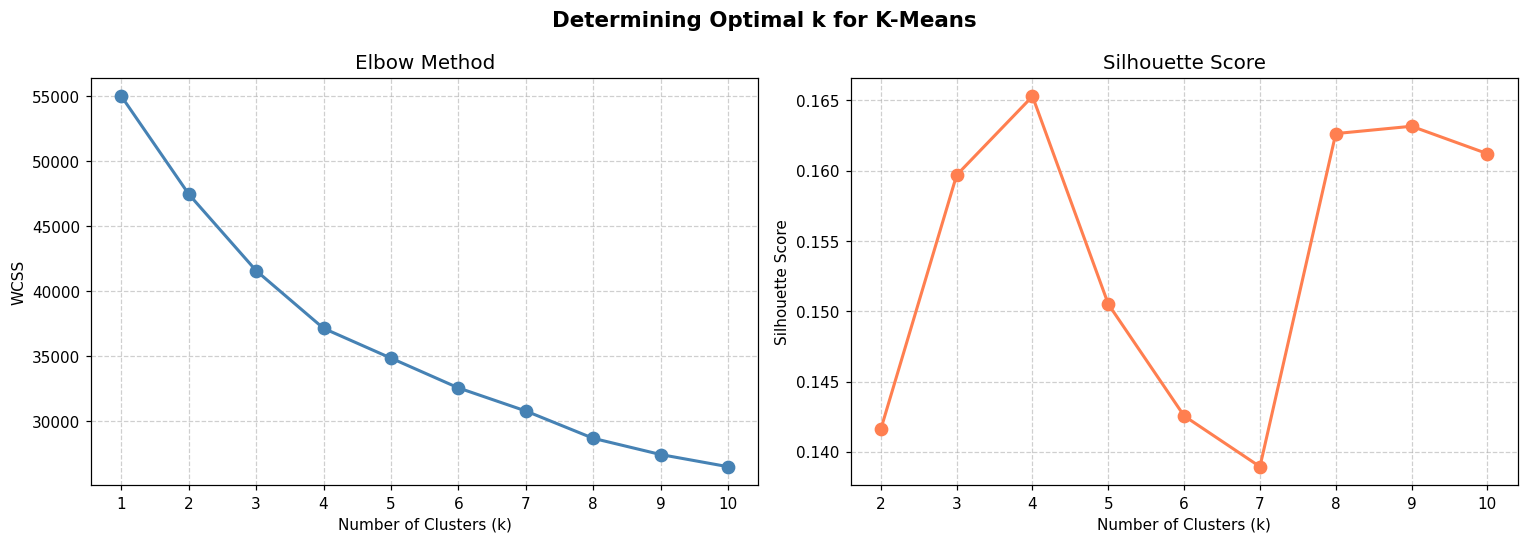

In [27]:
# Test multiple cluster numbers: Elbow + Silhouette in one go
wcss = []
sil_scores = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(data_scaled)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(data_scaled, labels))
    print(f"k={k}  |  WCSS: {km.inertia_:>10.1f}  |  Silhouette: {silhouette_score(data_scaled, labels):.4f}")

# Add k=1 WCSS manually for the elbow plot (silhouette needs at least k=2)
km1 = KMeans(n_clusters=1, random_state=42, n_init=10).fit(data_scaled)

# Plot both side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow
axes[0].plot([1] + list(k_range), [km1.inertia_] + wcss, marker='o', color='steelblue', linewidth=2, markersize=8)
axes[0].set_title('Elbow Method', fontsize=13)
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('WCSS')
axes[0].set_xticks([1] + list(k_range))
axes[0].grid(True, linestyle='--', alpha=0.6)

# Silhouette
axes[1].plot(k_range, sil_scores, marker='o', color='coral', linewidth=2, markersize=8)
axes[1].set_title('Silhouette Score', fontsize=13)
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_range))
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Determining Optimal k for K-Means', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

best_k = list(k_range)[sil_scores.index(max(sil_scores))]
print(f"\nBest k by silhouette: {best_k} (score: {max(sil_scores):.4f})")

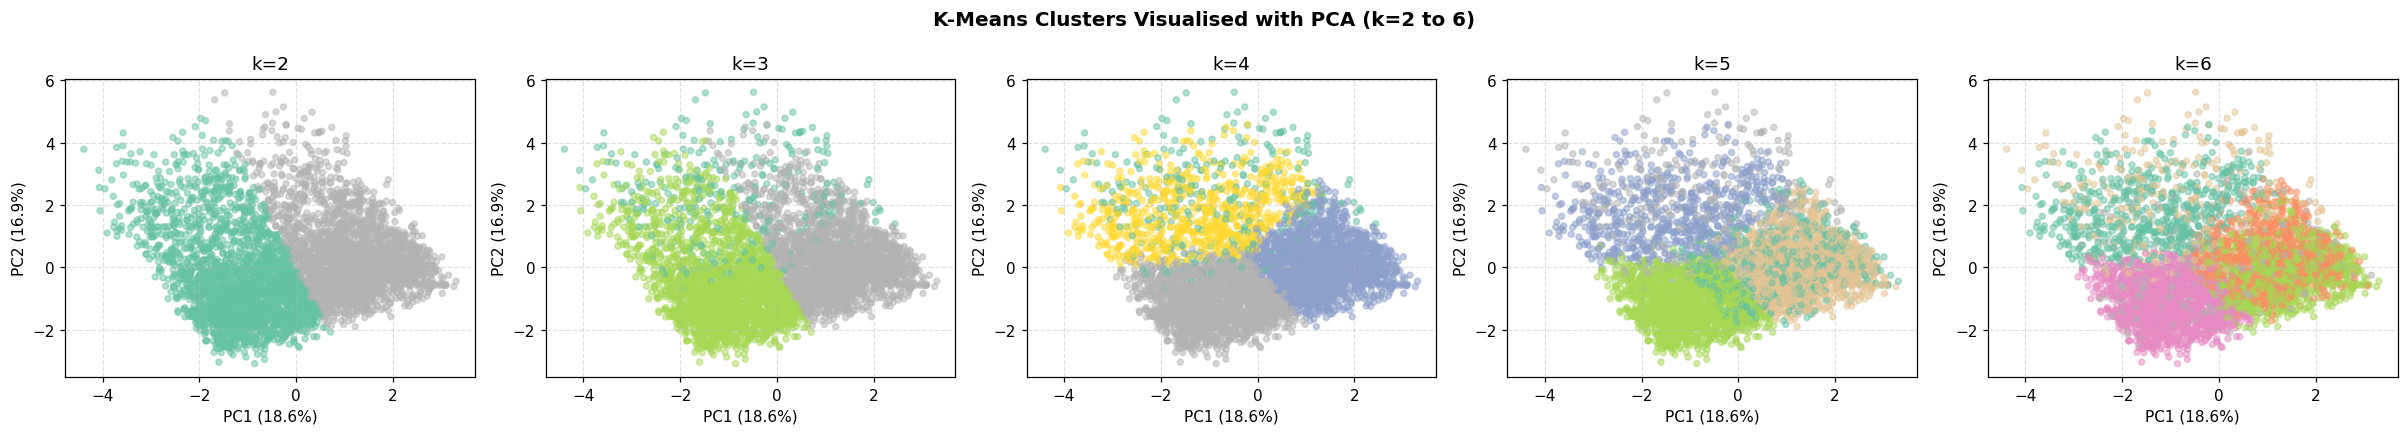

In [28]:
# Visualize clusters for k=2 to 6 using PCA
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(data_scaled)

fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for i, k in enumerate(range(2, 7)):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(data_scaled)
    
    axes[i].scatter(pca_result[:, 0], pca_result[:, 1],
                    c=labels, cmap='Set2', alpha=0.5, s=15)
    axes[i].set_title(f'k={k}', fontsize=12)
    axes[i].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    axes[i].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    axes[i].grid(True, linestyle='--', alpha=0.4)

plt.suptitle('K-Means Clusters Visualised with PCA (k=2 to 6)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [29]:
# Choose k by silhouette, rather than hardcoding a conflicting value.
optimal_k = best_k

kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_cluster['Cluster'] = kmeans_final.fit_predict(data_scaled)

print(f"KMeans applied with k={optimal_k}")
print()
print("Cluster distribution (number of customers per cluster):")
print(df_cluster['Cluster'].value_counts().sort_index())

KMeans applied with k=4

Cluster distribution (number of customers per cluster):
Cluster
0     302
1    2024
2     739
3    1935
Name: count, dtype: int64


In [30]:
# ── Cluster Profiles ──
cluster_profiles = df_cluster.groupby('Cluster').mean().round(2)
print("Cluster Profiles (mean feature values per cluster):")
cluster_profiles

Cluster Profiles (mean feature values per cluster):
Out[30]: 
           Age  Experience  Income  ...  CD Account  Online  CreditCard
Cluster                             ...                                
0        45.70       20.57  104.59  ...         1.0    0.94        0.79
1        55.59       30.27   57.02  ...         0.0    0.60        0.28
2        43.69       18.69  144.56  ...         0.0    0.54        0.20
3        35.19        9.94   59.45  ...         0.0    0.56        0.27

[4 rows x 11 columns]


In [31]:
# ── Loan Acceptance Rate per Cluster ──
df_cluster['Personal Loan'] = loan_labels.values
loan_rate = df_cluster.groupby('Cluster')['Personal Loan'].mean().round(3)
print("Loan acceptance rate per cluster:")
print(loan_rate)
df_cluster.drop(columns=['Personal Loan'], inplace=True)

Loan acceptance rate per cluster:
Cluster
0    0.464
1    0.033
2    0.284
3    0.033
Name: Personal Loan, dtype: float64


In [32]:
# ── Silhouette Score for chosen k ──
sil_final = silhouette_score(data_scaled, df_cluster['Cluster'])
print(f"Silhouette Score for k={optimal_k}: {sil_final:.4f}")

Silhouette Score for k=4: 0.1653


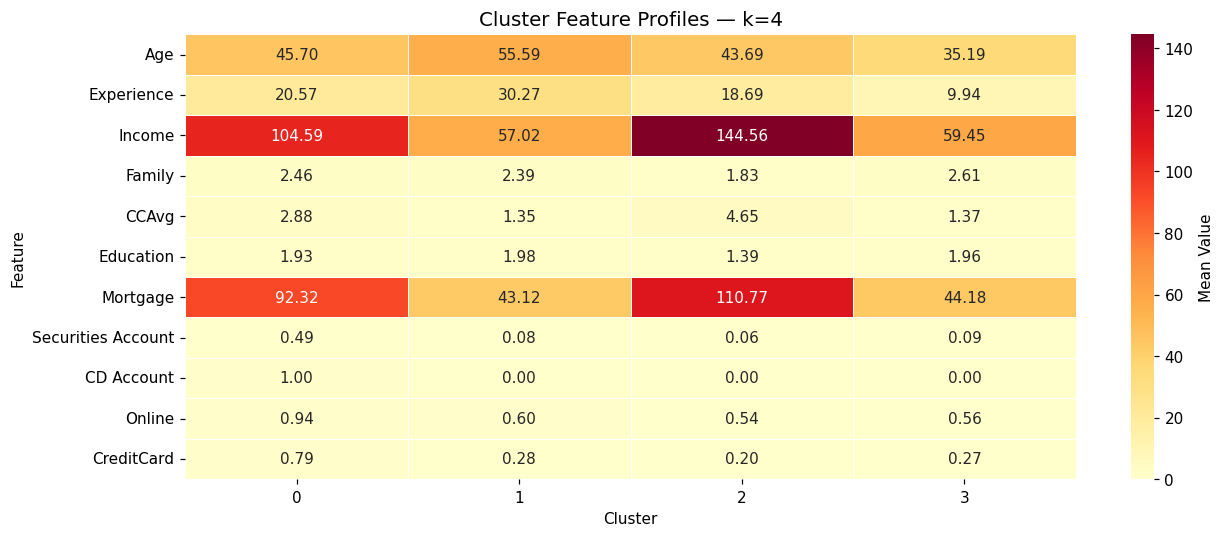

In [33]:
# ── Heatmap of Cluster Profiles ──
plt.figure(figsize=(12, 5))
sns.heatmap(cluster_profiles.T, annot=True, fmt='.2f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label': 'Mean Value'})
plt.title(f'Cluster Feature Profiles — k={optimal_k}', fontsize=13)
plt.xlabel('Cluster')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [34]:
import json, pickle
from sklearn.metrics import accuracy_score, f1_score
summary = pd.DataFrame([
    {'model': 'KNN', 'test_accuracy': accuracy_score(y_test, y_pred_knn),
     'test_f1': f1_score(y_test, y_pred_knn), 'training_cv_accuracy': knn_search.best_score_},
    {'model': 'ANN', 'test_accuracy': accuracy_score(y_test, y_pred_ann.ravel()),
     'test_f1': f1_score(y_test, y_pred_ann.ravel()), 'training_cv_accuracy': None}
])
summary.to_csv(RESULTS / 'test_comparison.csv', index=False)
print(summary.to_string(index=False))
for name, pred in [('KNN', y_pred_knn), ('ANN', y_pred_ann.ravel())]:
    (RESULTS / (name + '_test_report.json')).write_text(json.dumps(
        classification_report(y_test, pred, output_dict=True, zero_division=0), indent=2))
with open(ARTIFACTS / 'knn_pipeline.pkl', 'wb') as f: pickle.dump(knn_final, f)
with open(ARTIFACTS / 'ann_preprocessor.pkl', 'wb') as f: pickle.dump(ann_preprocessor, f)
ann.save(ARTIFACTS / 'ann.keras')
with open(ARTIFACTS / 'clustering.pkl', 'wb') as f:
    pickle.dump({'scaler': cluster_scaler, 'model': kmeans_final}, f)
cluster_profiles.to_csv(RESULTS / 'cluster_profiles.csv')
loan_rate.to_csv(RESULTS / 'cluster_loan_rates.csv')
pd.DataFrame({'k': list(k_range), 'silhouette': sil_scores, 'inertia': wcss}).to_csv(
    RESULTS / 'clustering_search.csv', index=False)


model  test_accuracy  test_f1  training_cv_accuracy
  KNN       0.965932 0.795181              0.962898
  ANN       0.969940 0.843750                   NaN
